# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import HistAerialDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/HistAerial/100x100_overlap_0percent/",
    "csv_file": "./data/HistAerial/100x100_overlap_0percent/train6k.txt",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = HistAerialDataset(dataset_config)

## Show images from the dataset

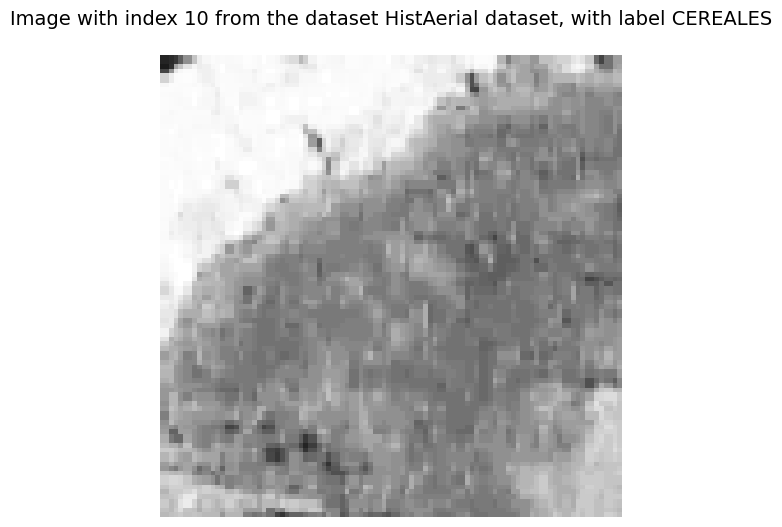

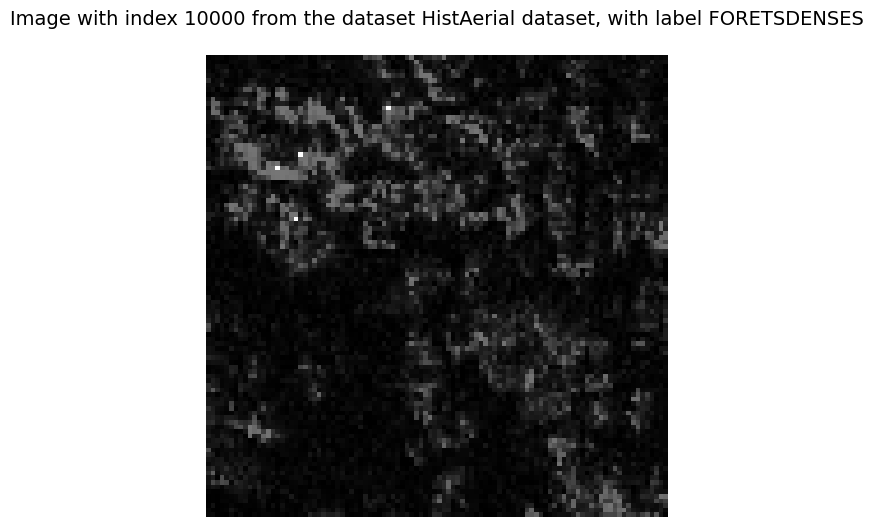

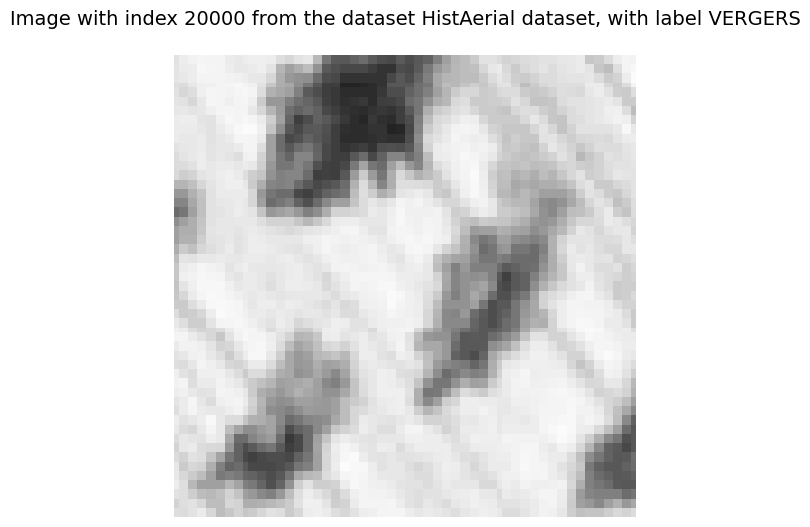

In [27]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(10000)
fig3 = dataset.show_image(20000)

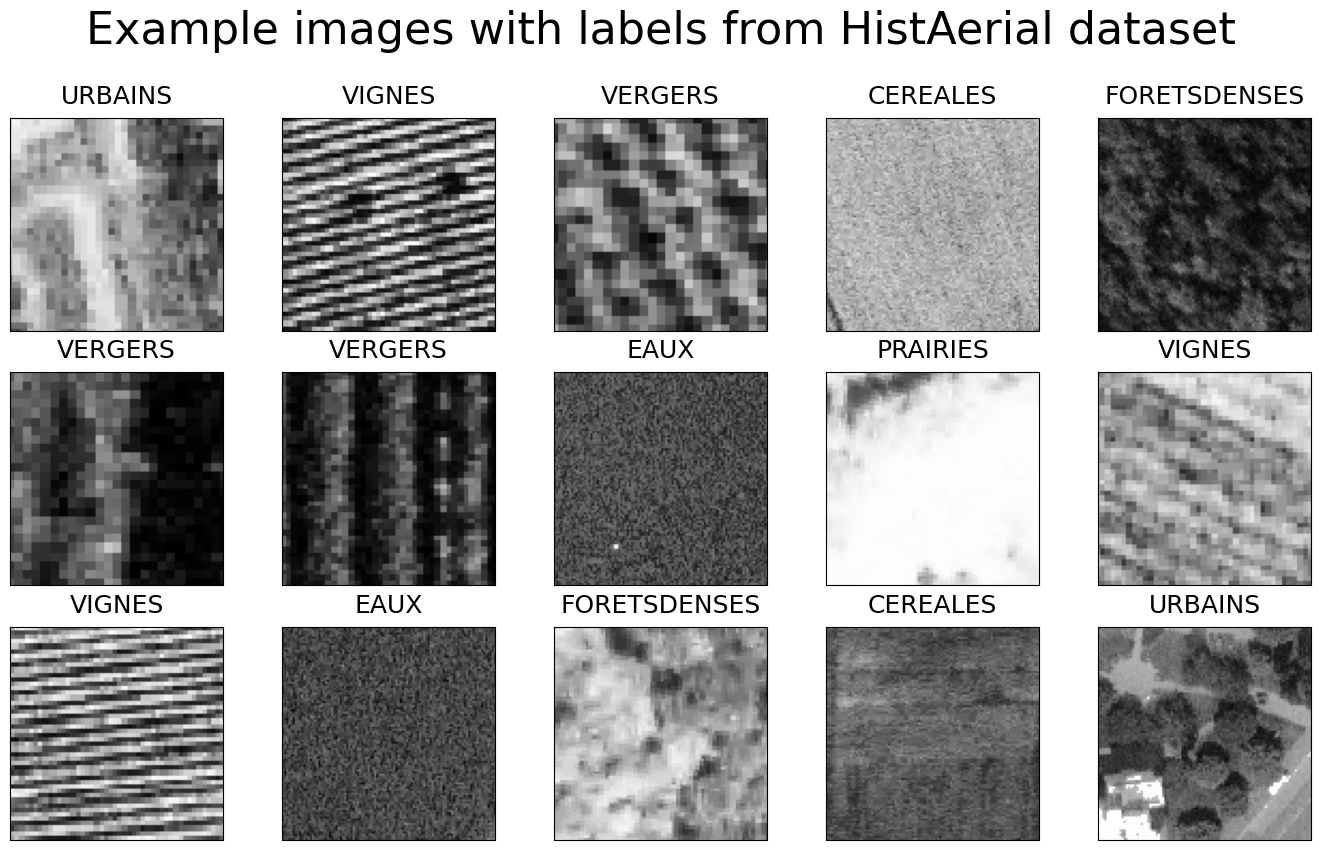

In [21]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [37]:
dataset.show_samples()

,File name,Label
0,CEREALES/53_31x20.png,CEREALES
1,CEREALES/31_22x57.png,CEREALES
2,CEREALES/43_15x25.png,CEREALES
3,CEREALES/34_61x42.png,CEREALES
4,CEREALES/43_20x38.png,CEREALES
5,CEREALES/5_66x29.png,CEREALES
6,CEREALES/10_27x15.png,CEREALES
7,CEREALES/46_54x13.png,CEREALES
8,CEREALES/43_41x21.png,CEREALES
9,CEREALES/11_56x14.png,CEREALES


In [43]:
dataset.data_distribution_table()

,Label,Count
0,CEREALES,3780
1,EAUX,3780
2,FORETSDENSES,3780
3,PRAIRIES,3780
4,URBAINS,3780
5,VERGERS,3780
6,VIGNES,3780


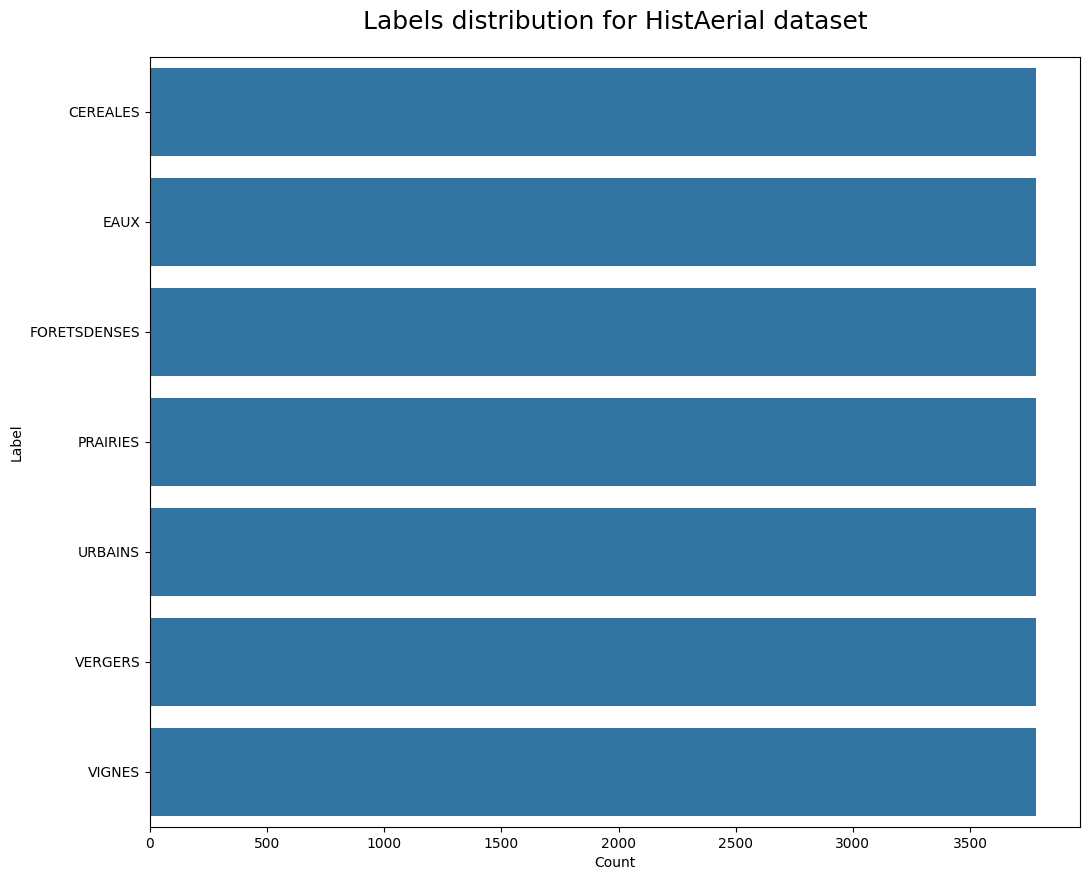

In [44]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/HistAerial/100x100_overlap_0percent/",
    "csv_file": "./data/HistAerial/100x100_overlap_0percent/train6k.txt",
}

train_dataset = HistAerialDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/HistAerial/100x100_overlap_0percent/",
    "csv_file": "./data/HistAerial/100x100_overlap_0percent/val6k.txt",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = HistAerialDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(26460, 11340)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/HistAerial/"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-28 09:37:03,478 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-28 09:37:03,688 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-28 09:37:05,410 INFO Starting training.
training: 100%|██████████| 827/827 [03:28<00:00,  3.97it/s]
2025-05-28 09:40:33,957 INFO epoch: 1, time: 208, loss:  0.50806
testing on train set: 100%|██████████| 827/827 [01:15<00:00, 10.99it/s]
2025-05-28 09:41:51,413 INFO Accuracy:0.8863567649281935, Precision Micro:0.8863567649281935, Precision Macro:0.8886336662891006, Precision Weighted:0.8886336662891005, Precision per Class:[0.73079538 0.94400837 0.87778652 0.77457169 0.91333149 0.98866632
 0.9912759 ], Recall Micro:0.8863567649281935, Recall Macro:0.8863567649281936, Recall Weighted:0.8863567649281936, Recall per Class:[0.8531746  0.95449735 0.88544974 0.68174603 0.87539683 0.99232804
 0.96190476], F1_score Micro:0.8863567649281929, F1_score Macro:0.8863012117091559, F1_score Weighted:0.8863012117091558, F1_score per Class:[0.78725741 0.94922389 0.88160148 0.72520051 0.89396191 0.99049379
 0.9763695 ]
testing on validation set: 100%|██████████| 355/355 [00:32<00:00, 10.97it/s]
2

0.24422886360574653

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/HistAerial/100x100_overlap_0percent/",
    "csv_file": "./data/HistAerial/100x100_overlap_0percent/test6k.txt",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = HistAerialDataset(test_dataset_config)
model_path = "./data/experiments/HistAerial/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-28 10:30:10,082 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/HistAerial/checkpoint.pth.tar
2025-05-28 10:30:10,359 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/HistAerial/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 263/263 [00:13<00:00, 19.24it/s]


[{'Accuracy': 0.8847619047619047},
 {'Precision Micro': 0.8847619047619047,
  'Precision Macro': 0.887277748312969,
  'Precision Weighted': 0.8872777483129689,
  'Precision per Class': array([0.86831276, 0.96833333, 0.81942337, 0.73225806, 0.83282675,
         0.99661591, 0.99317406])},
 {'Recall Micro': 0.8847619047619047,
  'Recall Macro': 0.8847619047619049,
  'Recall Weighted': 0.8847619047619047,
  'Recall per Class': array([0.70333333, 0.96833333, 0.9       , 0.75666667, 0.91333333,
         0.98166667, 0.97      ])},
 {'F1_score Micro': 0.8847619047619042,
  'F1_score Macro': 0.8841917747442546,
  'F1_score Weighted': 0.8841917747442544,
  'F1_score per Class': array([0.7771639 , 0.96833333, 0.85782367, 0.7442623 , 0.87122417,
         0.9890848 , 0.98145025])}]

## Predictions

2025-05-28 10:30:42,596 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/HistAerial/checkpoint.pth.tar
2025-05-28 10:30:42,850 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/HistAerial/checkpoint.pth.tar at epoch 11


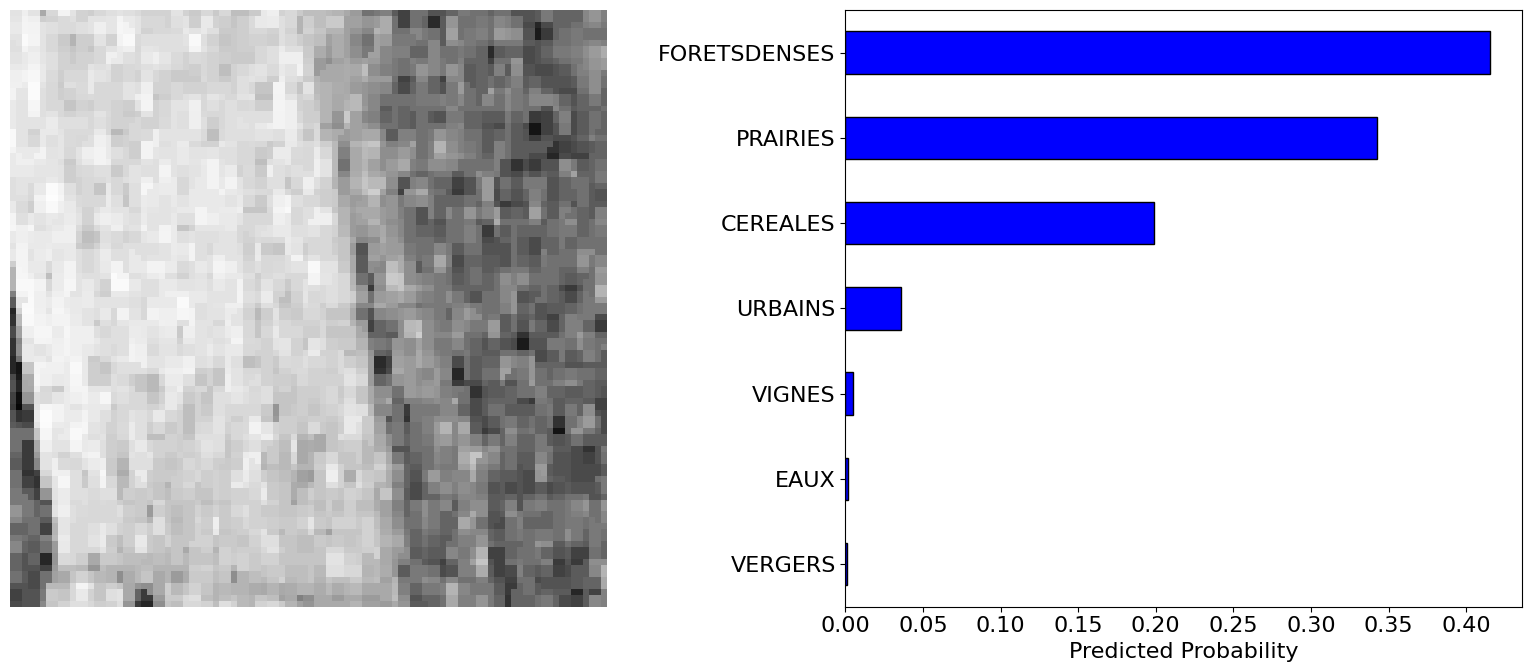

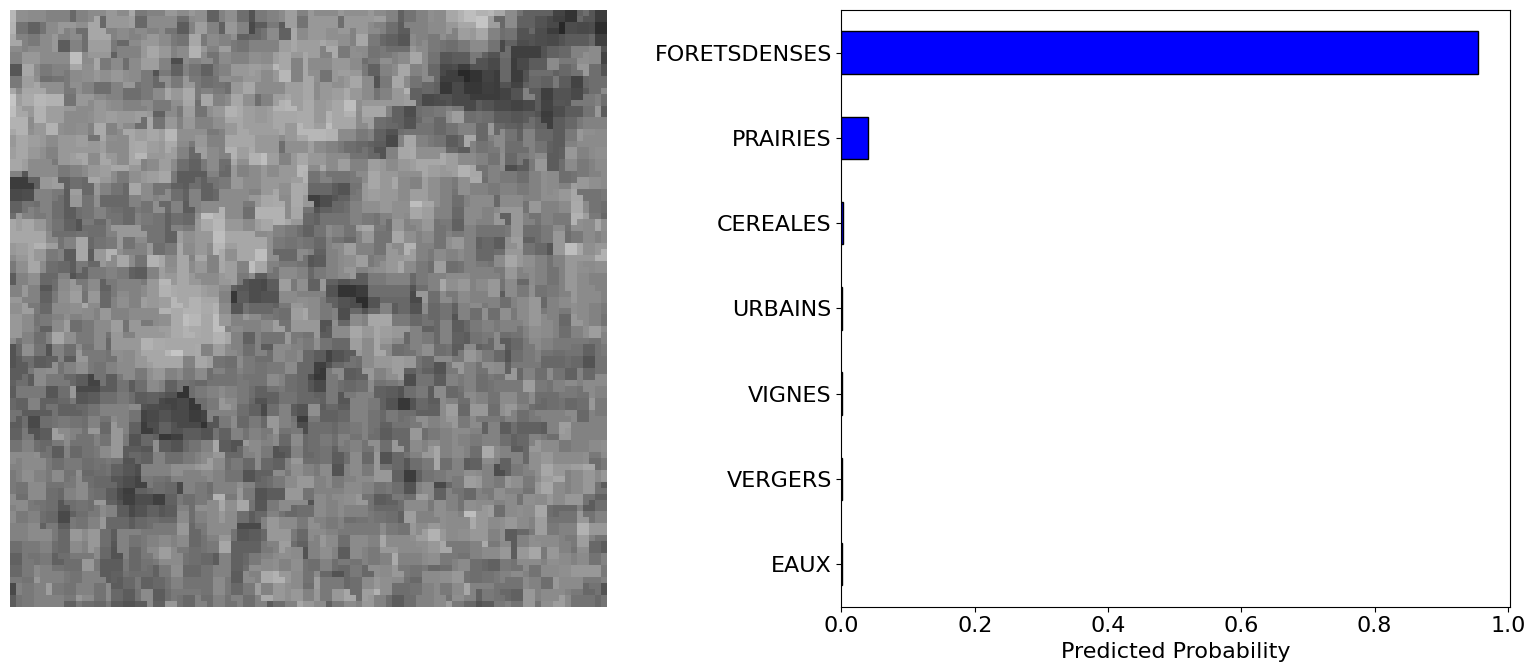

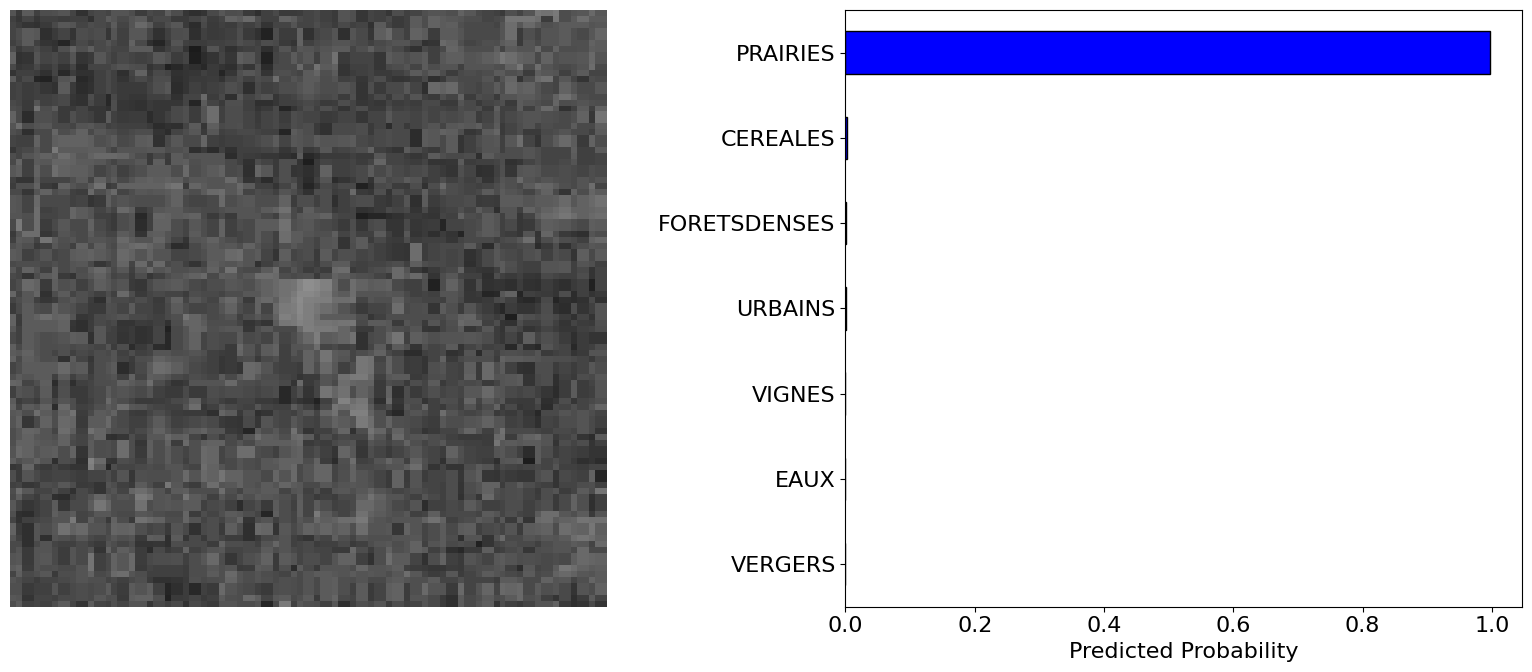

In [ ]:
labels = ["CEREALES","EAUX","FORETSDENSES","PRAIRIES","URBAINS","VERGERS","VIGNES"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/HistAerial/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/HistAerial/100x100_overlap_0percent/CEREALES/10_43x18.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/HistAerial/100x100_overlap_0percent/FORETSDENSES/12_75x29.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/HistAerial/100x100_overlap_0percent/PRAIRIES/3_56x51.png')
fig = model.predict_image(image, labels, transform)